# 03 — Model training

Five model families are compared on the five FoM targets and on the full
`log10(Id)` curve:

1. polynomial ridge regression (PR)
2. decision tree (DT)
3. random forest (RFR)
4. LightGBM (LGBR)
5. PyTorch MLP (ANN)

Hyperparameters are selected with `RandomizedSearchCV` / `GridSearchCV` using
`GroupKFold` on device id. The notebook reads the saved metrics; it does not
retrain the models.

The reported **train_seconds** values use the final tuned settings and the
single-threaded BLAS environment described in the project README.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path.cwd()
if not (PROJECT / "data").exists():
    PROJECT = PROJECT.parent
METRICS = PROJECT / "results" / "metrics"
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.25})

m = pd.read_csv(METRICS / "model_comparison.csv")
best = pd.read_csv(METRICS / "best_models.csv")
prep = json.loads((PROJECT / "data" / "processed" / "preprocessing_info.json").read_text())

print("device split:", prep["n_devices"])
print("FoM rows:", prep["n_fom_rows"])
print("curve rows:", prep["n_curve_rows"])
print("\nFoM test R² by target and model")
fom = m[m.task == "fom"]
display(fom.pivot(index="target", columns="model", values="test_r2").round(4))
print("\nCurve log10(Id) results")
display(m[m.task == "curve"][["model", "val_r2", "test_r2", "test_mae", "test_rmse", "train_seconds"]].sort_values("test_r2", ascending=False).round(4))
print("\nBest model per target (selected by validation R²)")
display(best[["task", "target", "model", "val_r2", "test_r2", "test_mae", "test_rmse", "train_seconds"]].round(4))

device split: {'train': 344, 'validation': 74, 'test': 73}
FoM rows: {'train': 888, 'validation': 193, 'test': 187}
curve rows: {'train': 85248, 'validation': 18528, 'test': 17952}

FoM test R² by target and model


model,ann,decision_tree,lightgbm,polynomial,random_forest
target,,,,,
SS_min_mV_per_dec,0.9461,0.6851,0.9052,0.9575,0.8129
Vth_V,0.8753,0.6596,0.8657,0.8680,0.8075
log10_Ioff,0.9964,0.9433,0.9929,0.9969,0.9778
log10_Ion,0.9851,0.8060,0.9666,0.9935,0.8926
log10_gm_max,0.9878,0.8098,0.9709,0.9950,0.9145



Curve log10(Id) results


,model,val_r2,test_r2,test_mae,test_rmse,train_seconds
29,ann,0.9993,0.9993,0.0569,0.0820,102.1194
28,lightgbm,0.9906,0.9915,0.2104,0.2869,7.7572
27,random_forest,0.9900,0.9885,0.2312,0.3349,259.5241
26,decision_tree,0.9816,0.9789,0.3169,0.4529,3.0805
25,polynomial,0.9602,0.9641,0.4721,0.5906,7.4506



Best model per target (selected by validation R²)


,task,target,model,val_r2,test_r2,test_mae,test_rmse,train_seconds
0,curve,log10_Id,ann,0.9993,0.9993,0.0569,0.0820,102.1194
1,fom,SS_min_mV_per_dec,ann,0.9703,0.9461,3.1471,4.8669,5.6661
2,fom,Vth_V,ann,0.9076,0.8753,0.0564,0.1067,3.8671
3,fom,log10_Ioff,ann,0.9925,0.9964,0.0279,0.0387,6.3988
4,fom,log10_Ion,polynomial,0.9891,0.9935,0.0530,0.0737,3.5815
5,fom,log10_gm_max,polynomial,0.9889,0.9950,0.0418,0.0557,0.1622


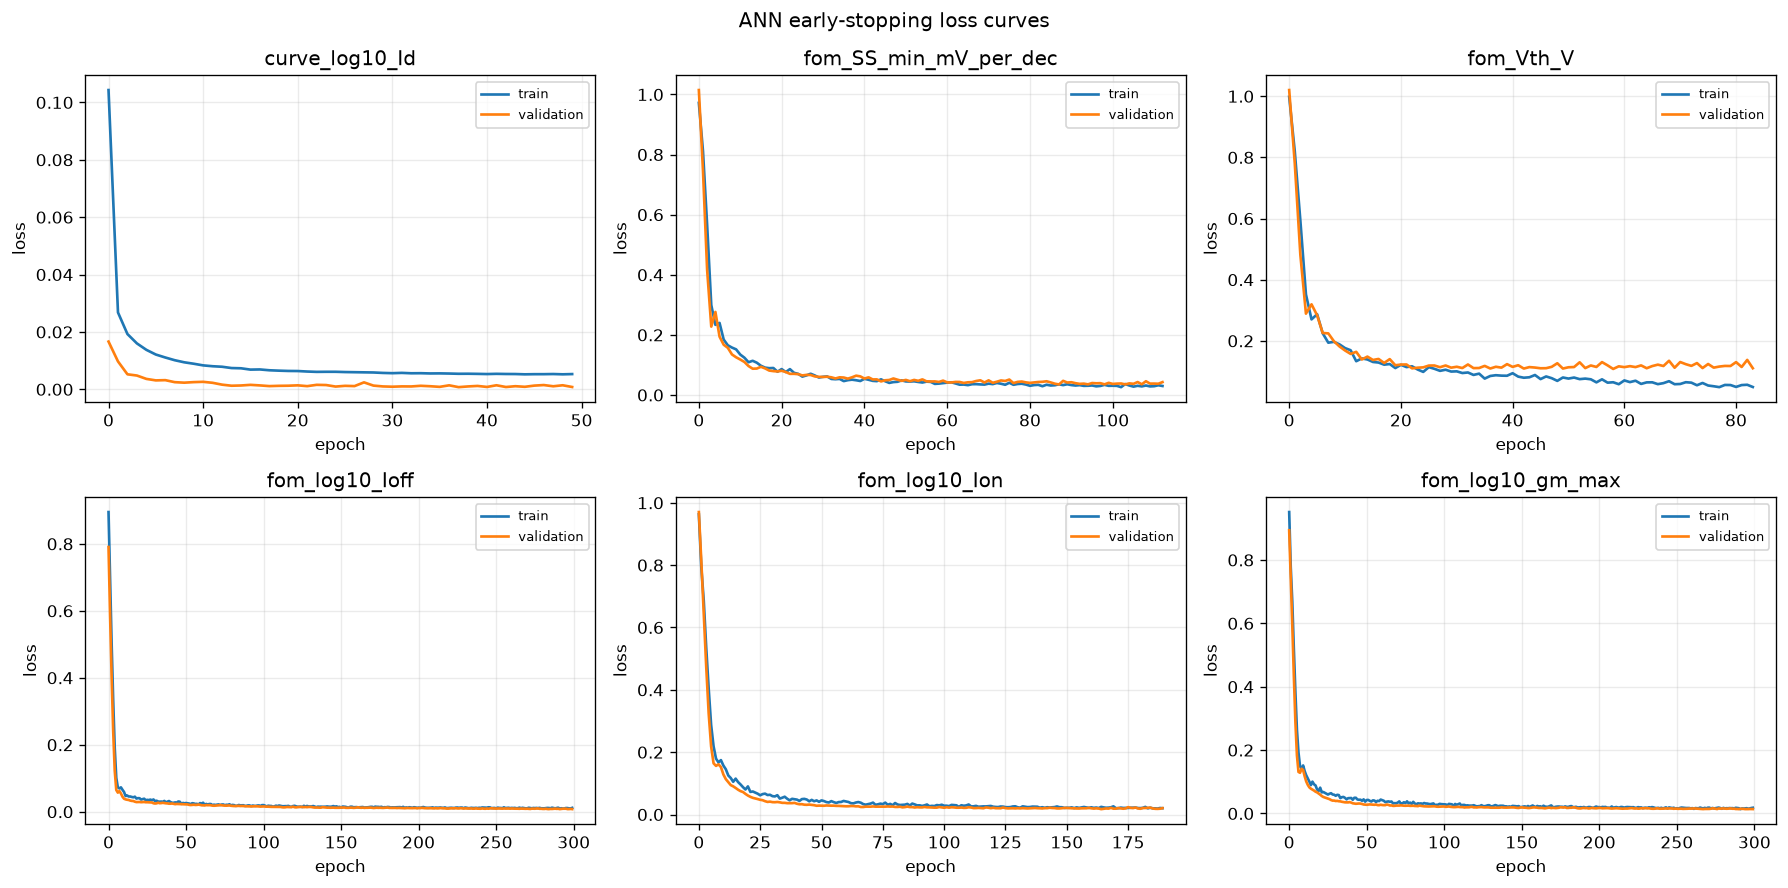

In [2]:
hist_files = sorted(METRICS.glob("*_ann_history.json"))
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, path in zip(axes.ravel(), hist_files):
    h = json.loads(path.read_text())
    ax.plot(h["train_loss"], label="train", lw=1.6)
    ax.plot(h["val_loss"], label="validation", lw=1.6)
    ax.set_title(path.stem.replace("_ann_history", ""))
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.legend(fontsize=8)
for ax in axes.ravel()[len(hist_files):]:
    ax.axis("off")
fig.suptitle("ANN early-stopping loss curves")
fig.tight_layout()
plt.show()

In [3]:
print("Search and runtime summary")
rows = []
for _, r in m.sort_values(["task", "target", "model"]).iterrows():
    rows.append({
        "task": r.task,
        "target": r.target,
        "model": r.model,
        "val_r2": r.val_r2,
        "test_r2": r.test_r2,
        "train_s": r.train_seconds,
    })
display(pd.DataFrame(rows).round(4))
print("\nTotal fits:", len(m))
print("FoM fresh-run wall clock (previous full run): 69.5 s for 25 fits")
print("Curve fresh-run wall clock (previous full run): 6 min 29 s")

Search and runtime summary


,task,target,model,val_r2,test_r2,train_s
0,curve,log10_Id,ann,0.9993,0.9993,102.1194
1,curve,log10_Id,decision_tree,0.9816,0.9789,3.0805
2,curve,log10_Id,lightgbm,0.9906,0.9915,7.7572
3,curve,log10_Id,polynomial,0.9602,0.9641,7.4506
4,curve,log10_Id,random_forest,0.9900,0.9885,259.5241
5,fom,SS_min_mV_per_dec,ann,0.9703,0.9461,5.6661
6,fom,SS_min_mV_per_dec,decision_tree,0.7336,0.6851,0.2039
7,fom,SS_min_mV_per_dec,lightgbm,0.9248,0.9052,0.4652
8,fom,SS_min_mV_per_dec,polynomial,0.9643,0.9575,0.1281
9,fom,SS_min_mV_per_dec,random_forest,0.8543,0.8129,4.9254



Total fits: 30
FoM fresh-run wall clock (previous full run): 69.5 s for 25 fits
Curve fresh-run wall clock (previous full run): 6 min 29 s


### Speed note

An early configuration oversubscribed the 16-core machine: random forest and
LightGBM were each allowed to use many threads while a 12-job outer search was
already running. That produced 39+ minute runs. The final configuration uses:

- outer `N_JOBS = 12`
- RF and LGBM `n_jobs = 1`
- RF/LGBM search iterations 12 (FoM) and 8 (curve)
- RF/LGBM `n_estimators ∈ {100, 200, 400}`
- LGBM `num_leaves ∈ {7, 15, 31}`, `max_bin = 63`
- `OMP_NUM_THREADS=1 MKL_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1`

This reduced the FoM run to about 70 seconds. The curve ANN remains the most
expensive fit because it trains on 85,248 rows.